<a href="https://colab.research.google.com/github/OmRohamare/stats_for_data/blob/main/Distributions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [24]:

import pandas as pd                    # load data, mean(), median(), mode()
import numpy as np                     # mean, median, weighted average
from scipy import stats                # trim_mean, gmean, hmean, mode
import matplotlib.pyplot as plt        # visualization
import seaborn as sns

In [25]:
cleaned = pd.read_csv('/content/drive/MyDrive/statsdata/house_sales_cleaned.csv', sep='\t')
cleaned

,DocumentDate,SalePrice,PropertyID,PropertyType,ym,zhvi_px,zhvi_idx,AdjSalePrice,NbrLivingUnits,SqFtLot,...,Bathrooms,Bedrooms,BldgGrade,YrBuilt,YrRenovated,TrafficNoise,LandVal,ImpsVal,ZipCode,NewConstruction
0,2014-09-16,280000,1000102,Multiplex,2014-09-01,405100,0.930836,300805.0,2,9373,...,3.00,6,7,1991,0,0,70000,229000,98002,False
1,2006-06-16,1000000,1200013,Single Family,2006-06-01,404400,0.929228,1076162.0,1,20156,...,3.75,4,10,2005,0,0,203000,590000,98166,True
2,2007-01-29,745000,1200019,Single Family,2007-01-01,425600,0.977941,761805.0,1,26036,...,1.75,4,8,1947,0,0,183000,275000,98166,False
3,2008-02-25,425000,2800016,Single Family,2008-02-01,418400,0.961397,442065.0,1,8618,...,3.75,5,7,1966,0,0,104000,229000,98168,False
4,2013-03-29,240000,2800024,Single Family,2013-03-01,351600,0.807904,297065.0,1,8620,...,1.75,4,7,1948,0,0,104000,205000,98168,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22662,2011-04-08,325000,9842300710,Single Family,2011-04-01,318700,0.732307,443803.0,1,5468,...,1.75,3,7,1951,0,0,201000,172000,98126,False
22663,2007-09-28,1580000,9845500010,Single Family,2007-09-01,433500,0.996094,1586196.0,1,23914,...,4.50,4,11,2000,0,1,703000,951000,98040,False
22664,2012-07-09,165000,9899200010,Single Family,2012-07-01,325300,0.747472,220744.0,1,11170,...,1.00,4,6,1971,0,0,92000,130000,98055,False
22665,2006-05-26,315000,9900000355,Single Family,2006-05-01,400600,0.920496,342207.0,1,6223,...,2.00,3,7,1939,0,0,103000,212000,98166,False


#A.Empirical

In [26]:
numeric_cols = cleaned.select_dtypes(include='number').columns.tolist()
print(numeric_cols)


['SalePrice', 'PropertyID', 'zhvi_px', 'zhvi_idx', 'AdjSalePrice', 'NbrLivingUnits', 'SqFtLot', 'SqFtTotLiving', 'SqFtFinBasement', 'Bathrooms', 'Bedrooms', 'BldgGrade', 'YrBuilt', 'YrRenovated', 'TrafficNoise', 'LandVal', 'ImpsVal', 'ZipCode']


# 1.Histogram


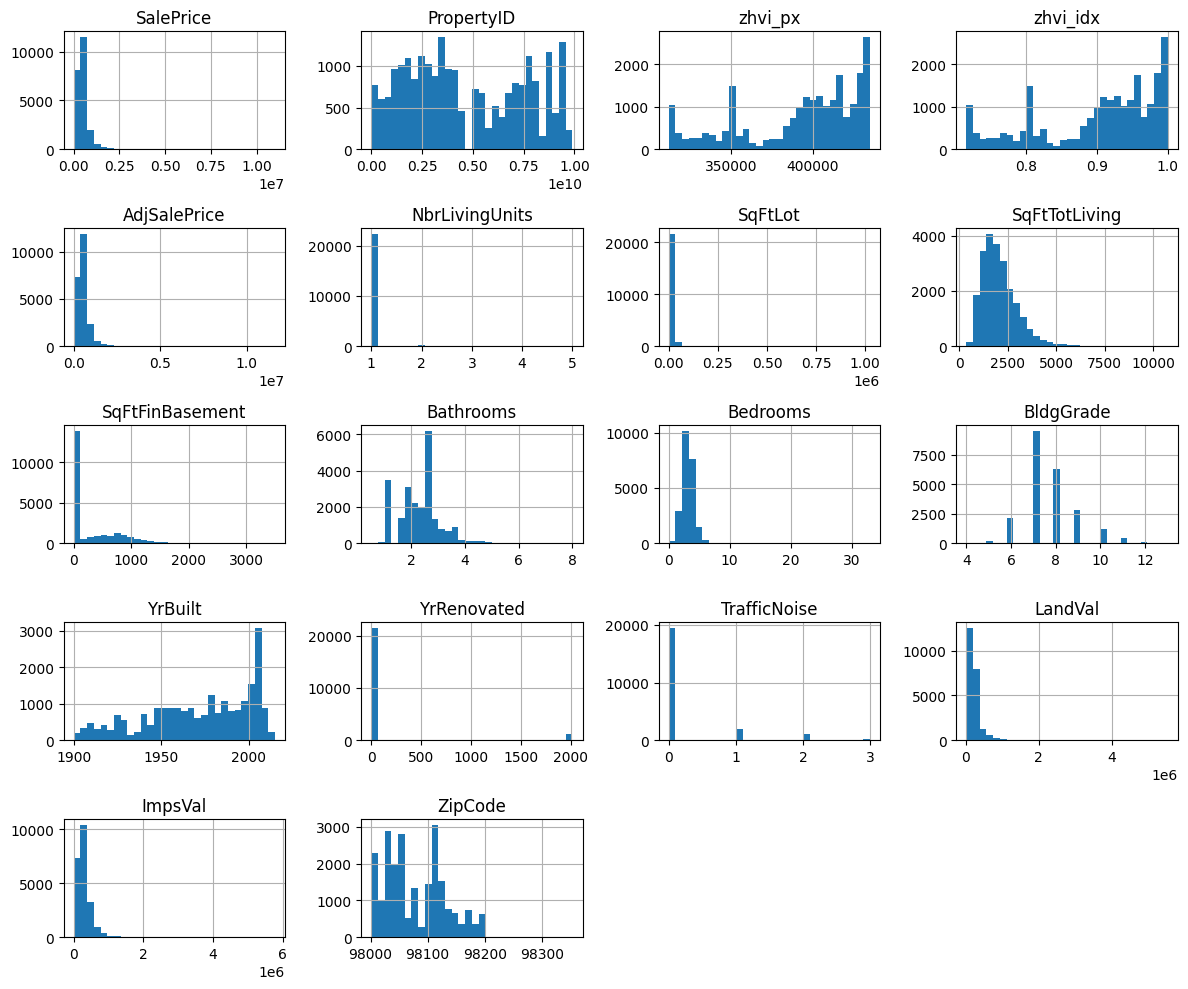

In [27]:
# Generates individual subplots automatically for all numeric columns
cleaned.hist(bins=30, figsize=(12, 10))

plt.tight_layout() # Prevents overlapping labels
plt.show()


# 2.KDE
A KDE plot (Kernel Density Estimate plot) is a chart that shows the probability distribution of a continuous variable using a smooth, continuous curve instead of discrete bars

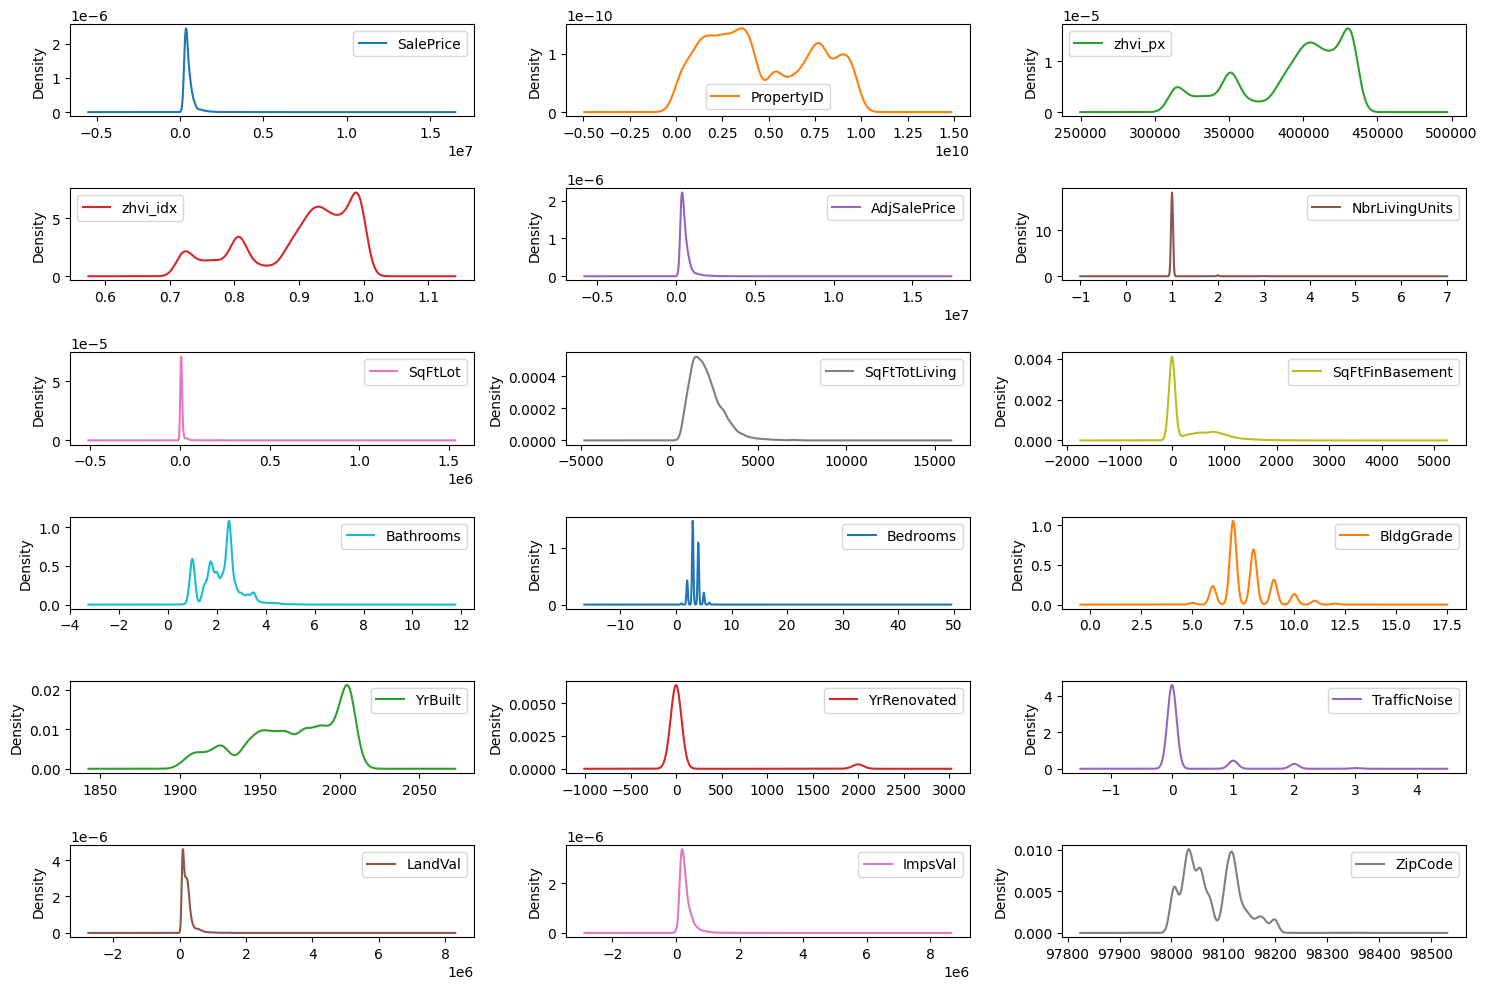

In [28]:
# Generate individual kernel density estimation (KDE) plots
# for every numeric column in the 'cleaned' DataFrame
cleaned.plot(
    kind='density',      # Specifies density (KDE) plots to visualize distributions
    subplots=True,       # Creates a separate subplot for each column
    layout=(-1, 3),      # Organizes subplots into a grid with 3 columns (-1 calculates rows automatically)
    sharex=False,        # Gives each subplot its own independent X-axis scale
    figsize=(15, 10)     # Sets the overall width and height of the figure window
)

# Automatically adjust subplot parameters to prevent overlapping labels/titles
plt.tight_layout()

# Render and display the final visualization window
plt.show()

# Empirical Cumulative Distribution Function (ECDF):
Displays the exact proportion or count of data observations falling at or below each unique value on a non-decreasing step curve

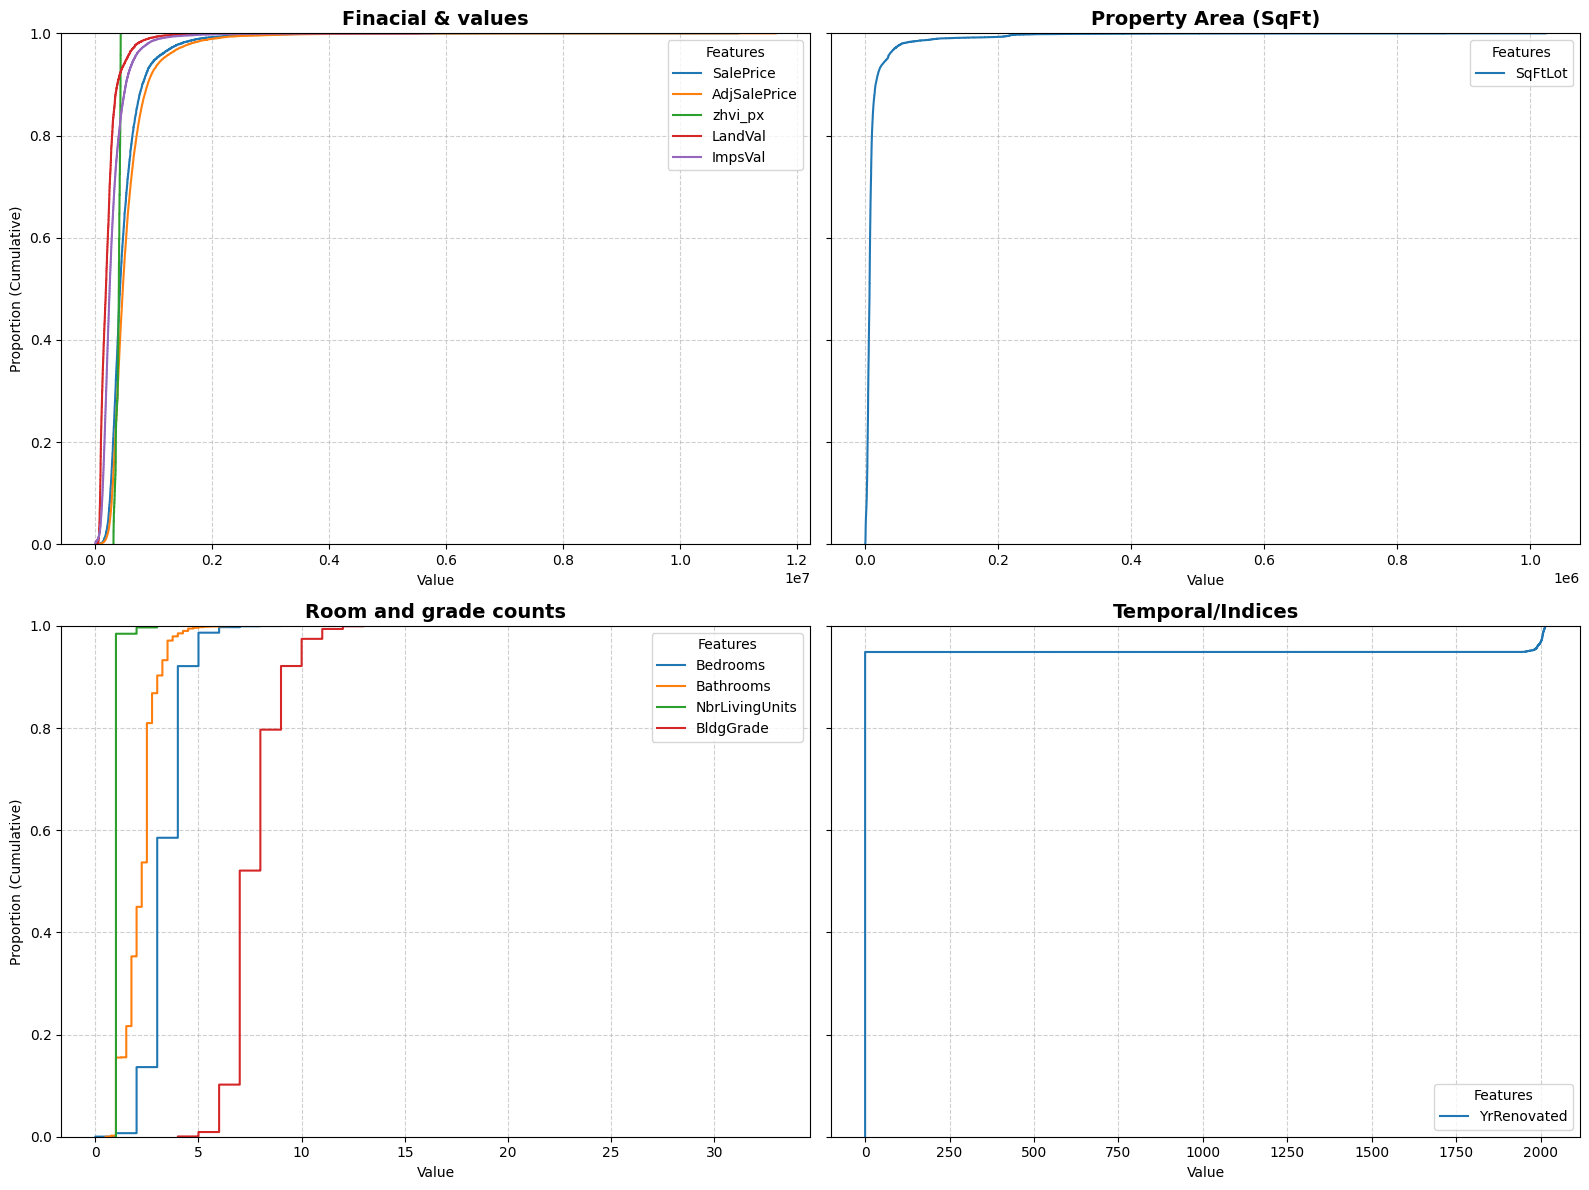

In [29]:
#Defining feature groups for readibility
price_cols= ["SalePrice","AdjSalePrice","zhvi_px","LandVal","ImpsVal"]
space_cols=["SqFtLot","SqFtToLiving","SqFtinBasement"]
time_cols=["YrBulit","YrRenovated","zhvu_idx"]
rooms_cols=["Bedrooms","Bathrooms","NbrLivingUnits","BldgGrade"]

all_groups=[price_cols,space_cols,rooms_cols,time_cols]
title=["Finacial & values", "Property Area (SqFt)",
       "Room and grade counts","Temporal/Indices"]

#Creating a 2x2 gird of subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12),sharey=True)
axes=axes.flatten()

for i, group in enumerate(all_groups):
  ax=axes[i]
  # Plot each column in the group (ignores missing columns gracefully)
  for col in group:
      if col in cleaned.columns:
         sns.ecdfplot(data=cleaned, x=col, ax=ax, label=col)

  ax.set_title(title[i], fontsize=14, fontweight='bold')
  ax.set_xlabel("Value")
  ax.set_ylabel("Proportion (Cumulative)")
  ax.legend(title="Features")
  ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


#Box Plot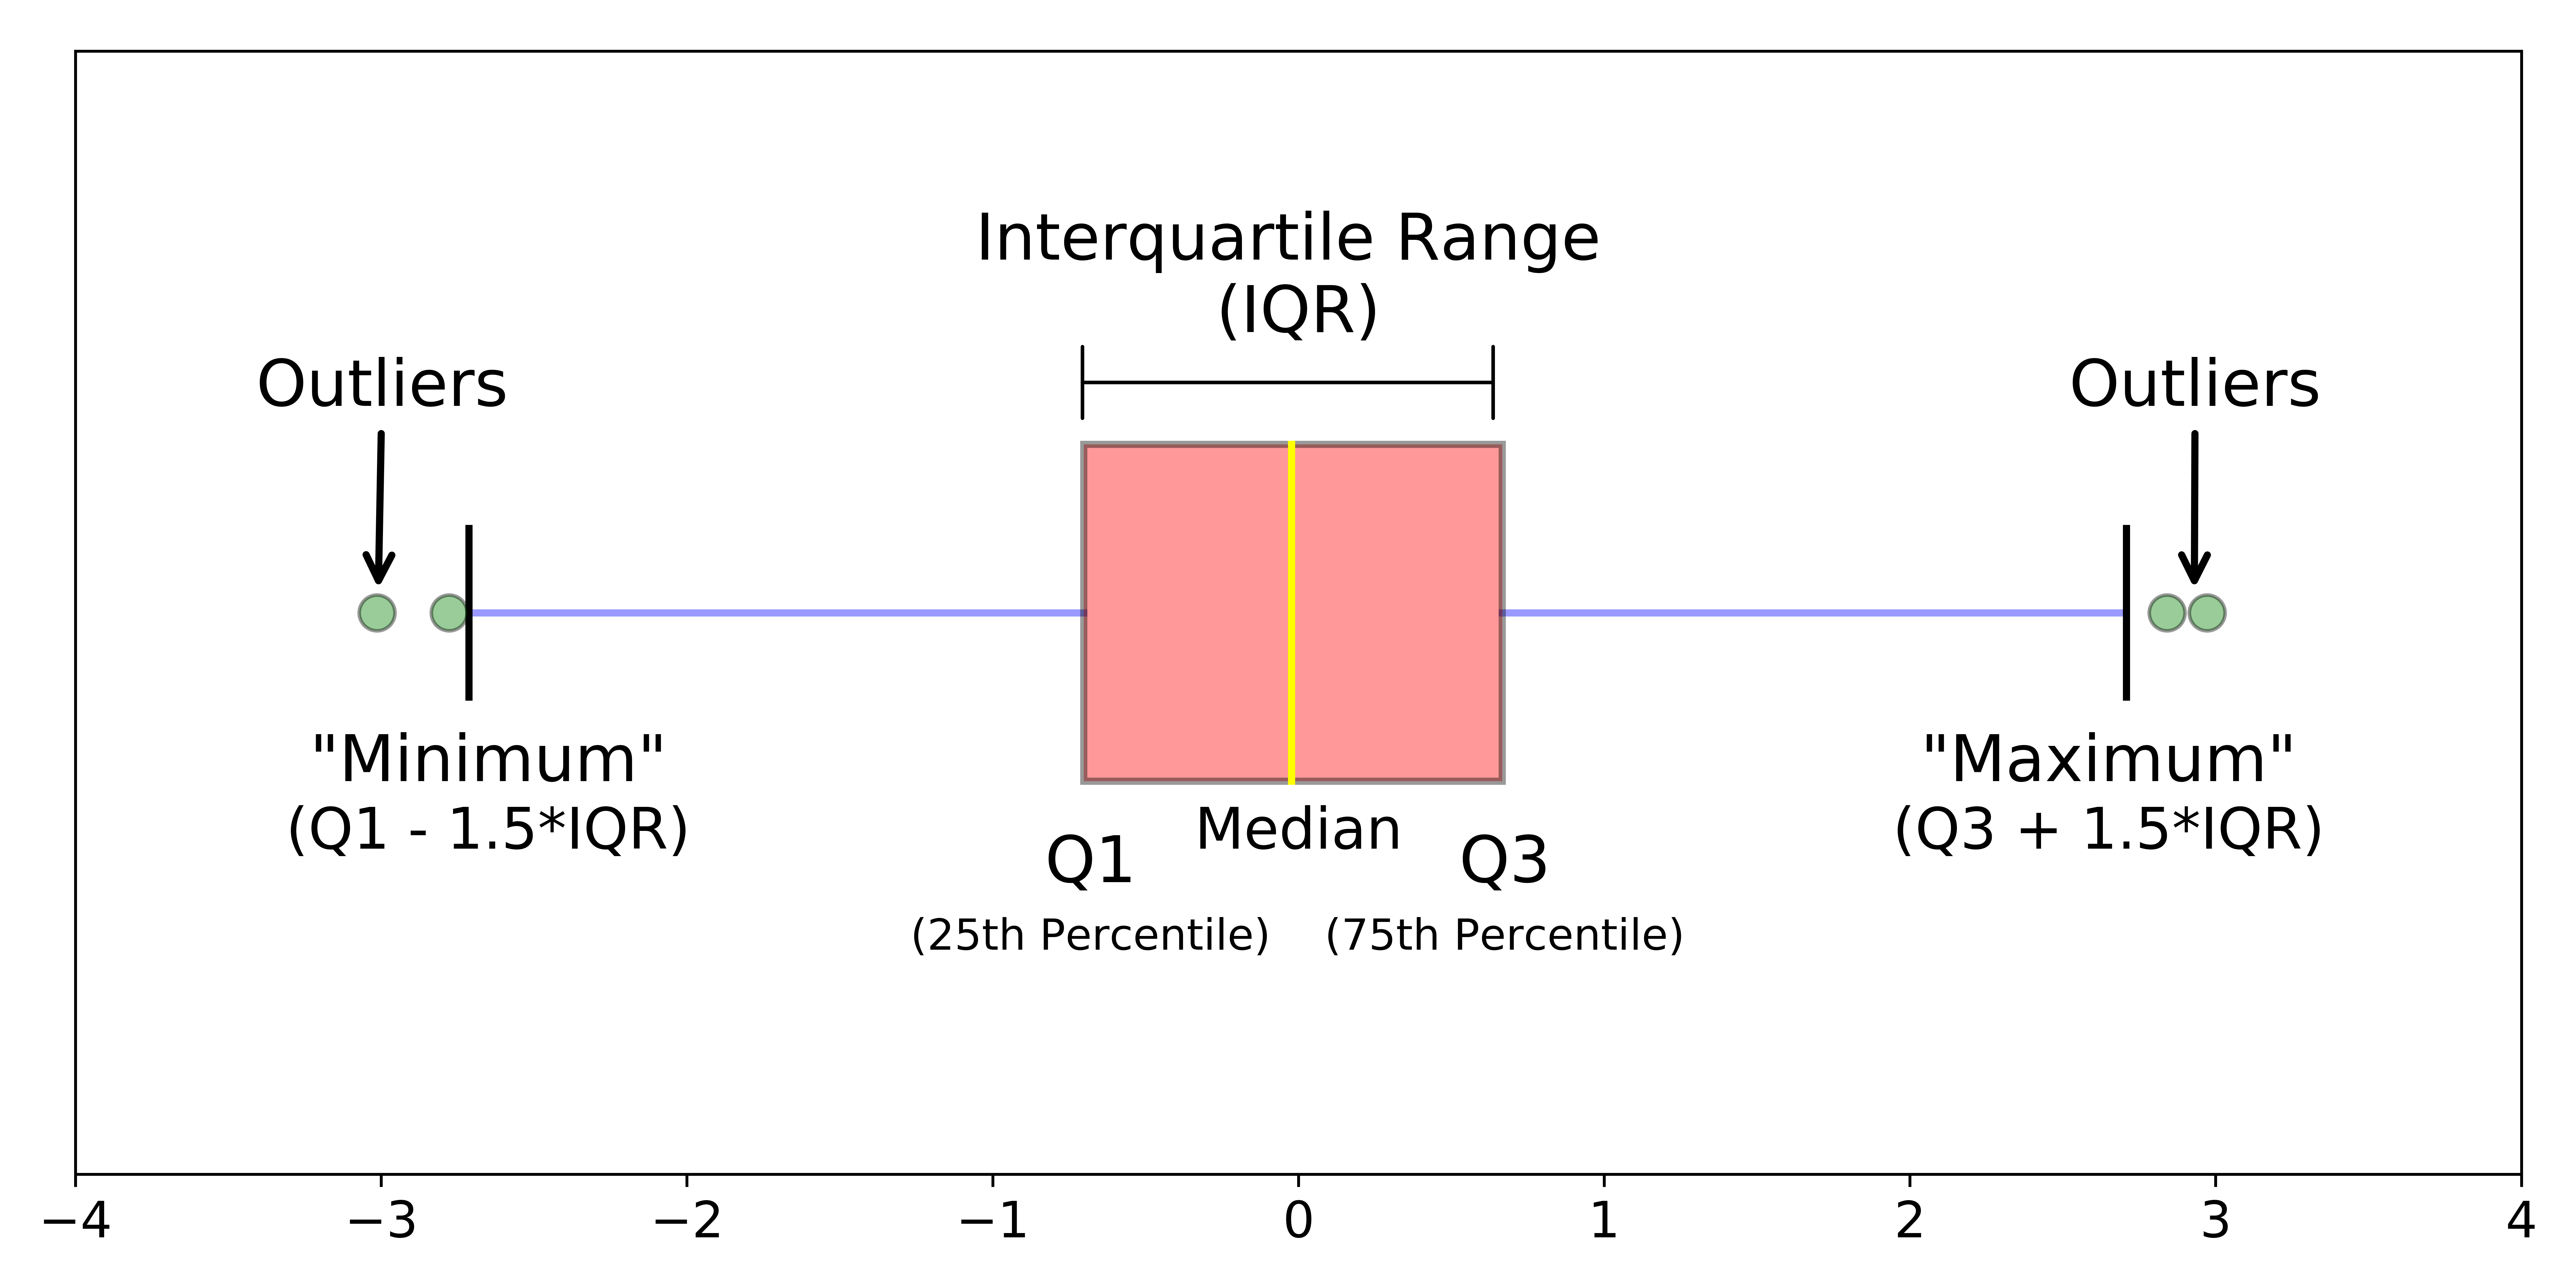

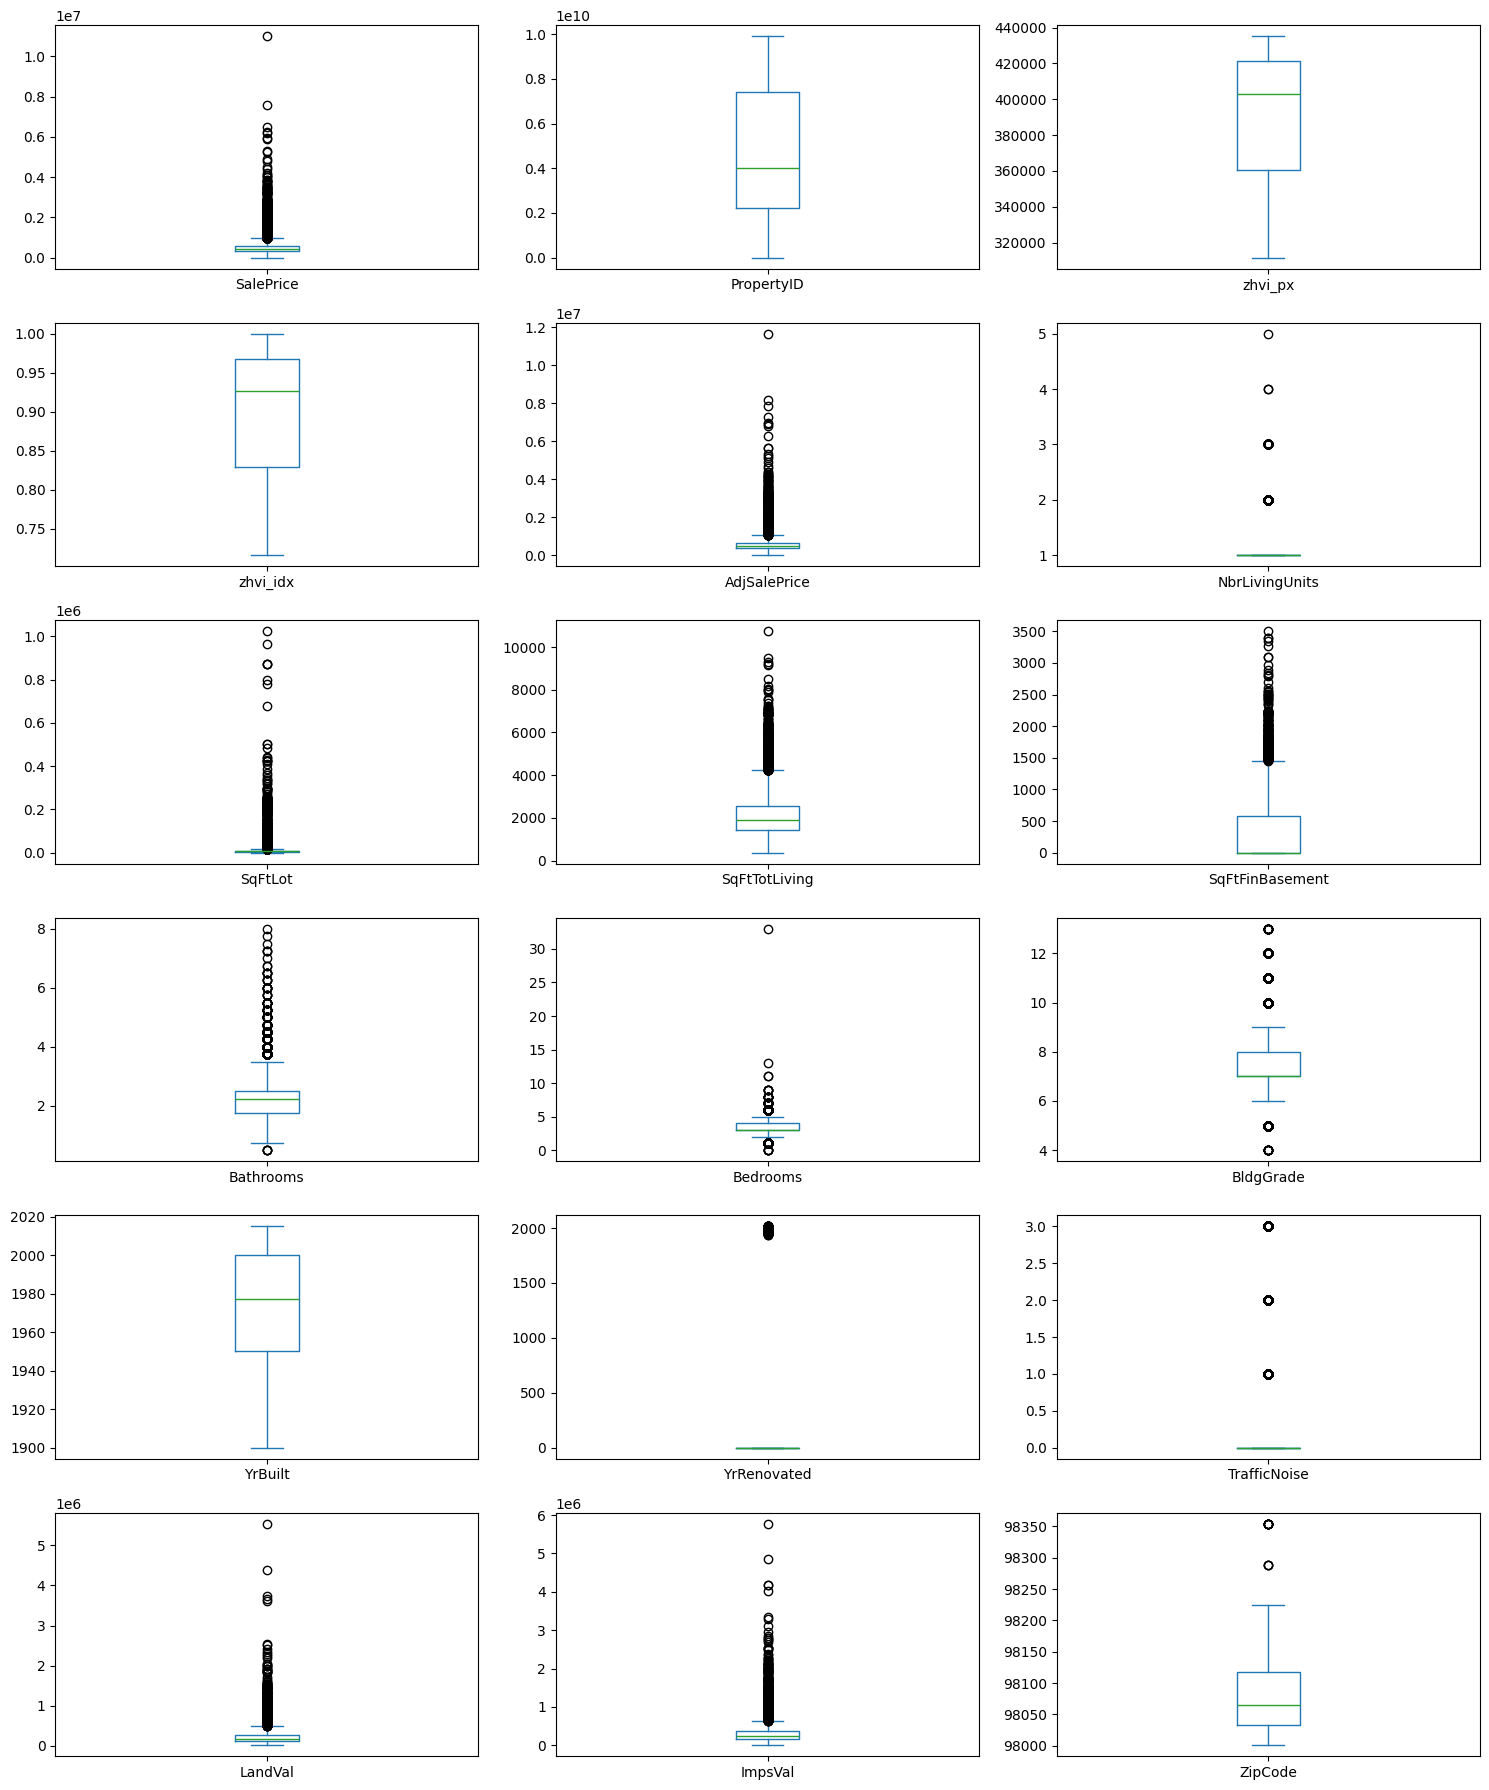

In [30]:
# 1. Calculate the number of rows dynamically
num_cols = len(cleaned.select_dtypes(include=['number']).columns)
num_rows = (num_cols + 2) // 3  # Rounds up to fit all columns into 3 columns

# 2. Plot with a valid positive integer layout
cleaned.plot(
    kind='box',
    subplots=True,
    layout=(num_rows, 3),
    sharex=False,
    figsize=(15, 3 * num_rows)  # Scales the height dynamically based on rows
)

plt.tight_layout()
plt.show()


#Violin Plot


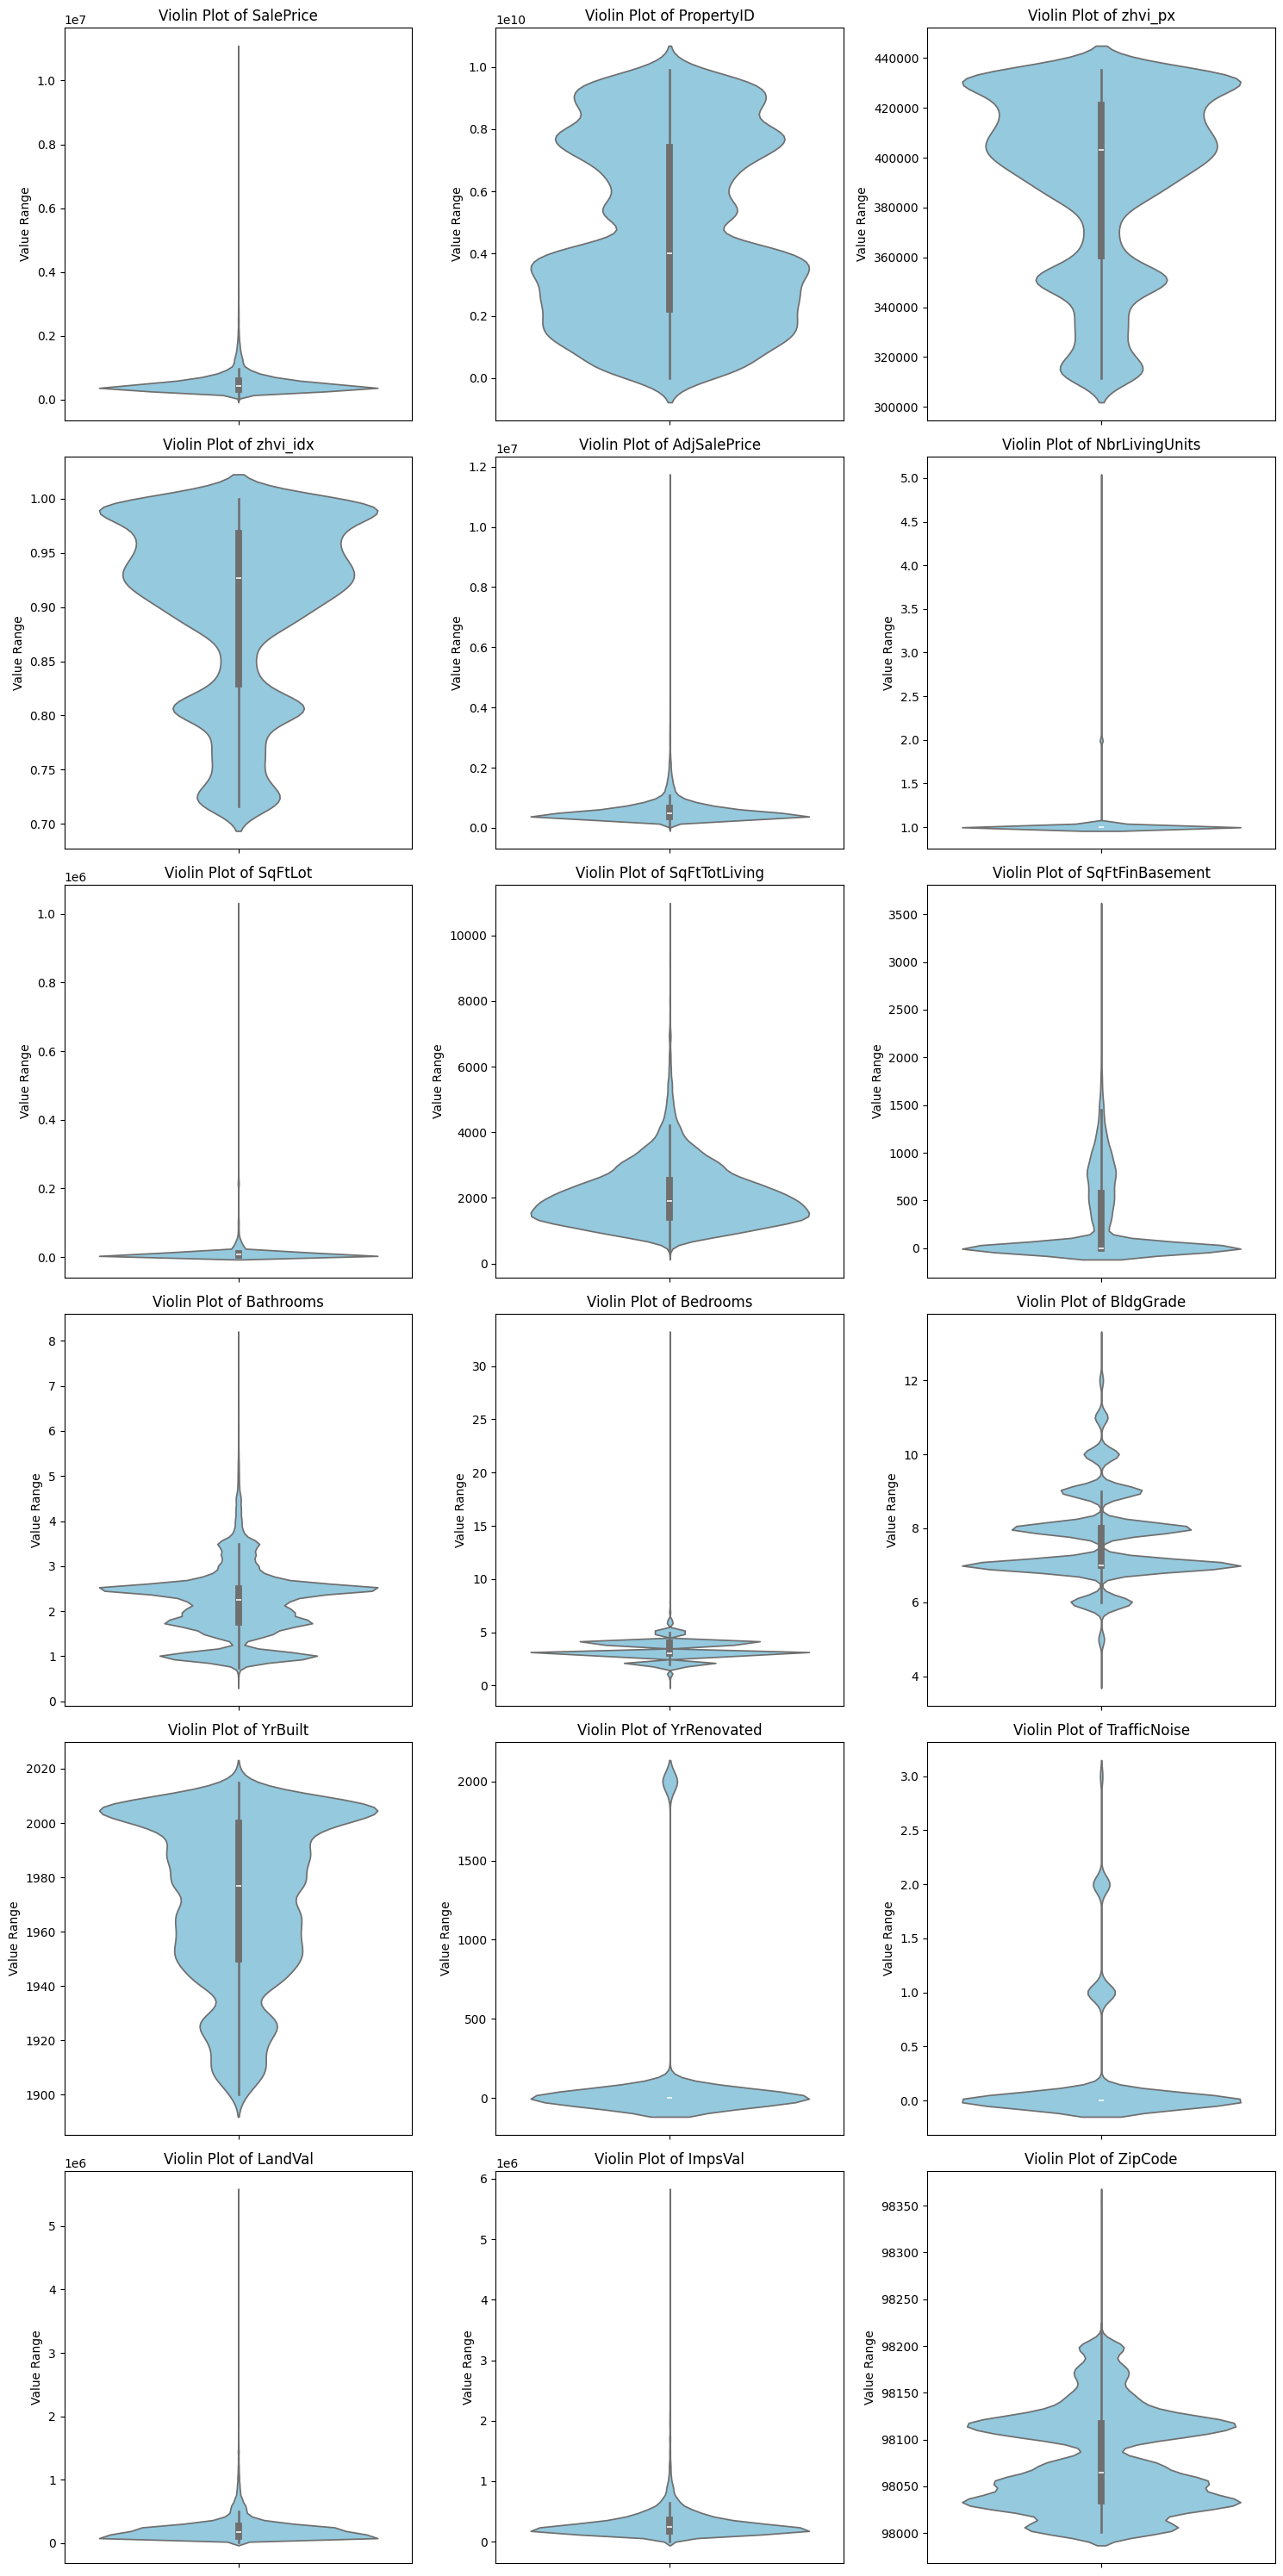

In [31]:
# 1. Isolate the numeric columns from your DataFrame
num_plots = len(numeric_cols)

# 2. Dynamically set up a grid layout (3 columns per row)
ncols = 3
nrows = (num_plots + ncols - 1) // ncols

# Fixed: Added multiplication operator (*) for figsize height calculation
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 5 * nrows))

# Flatten axes array so we can index it easily using a single loop
axes = axes.flatten()

# 3. Loop through columns and plot each on its own subplot
for i, col in enumerate(numeric_cols):
    # Fixed: Replaced 'palette' with 'color' to avoid the deprecation warning
    sns.violinplot(data=cleaned, y=col, ax=axes[i], color="skyblue")
    axes[i].set_title(f"Violin Plot of {col}")
    axes[i].set_ylabel("Value Range")

# 4. Remove any unused empty subplots if the grid isn't perfectly full
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#Split by PropertyType, NewConstruction, BldgGrade, TrafficNoise vs SalePrice


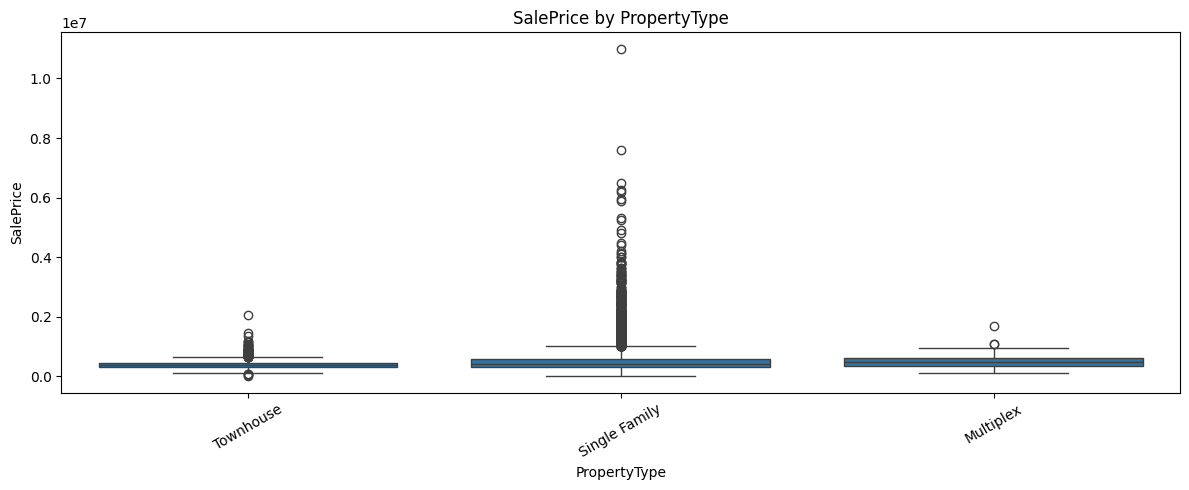

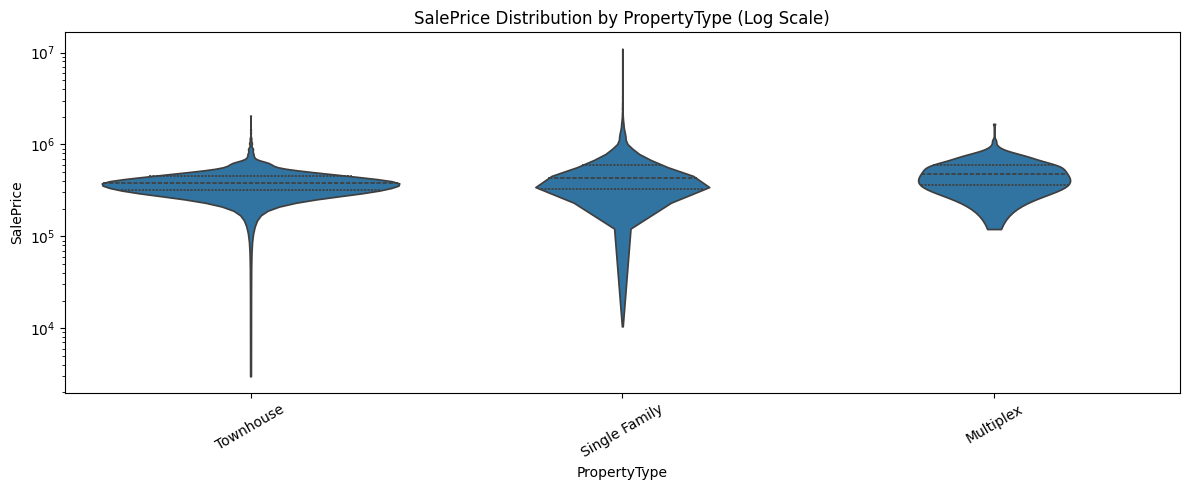


Summary by PropertyType
               count    median       mean        std
PropertyType                                        
Multiplex        256  478505.0  500257.07  191599.58
Single Family  20704  429500.0  517135.39  358544.72
Townhouse       1707  379900.0  398710.47  136009.96


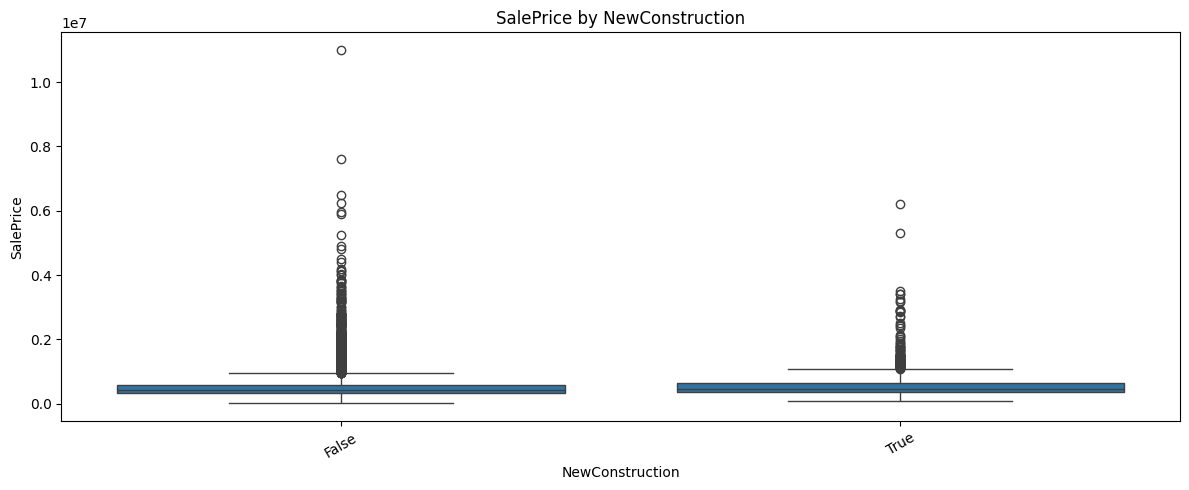

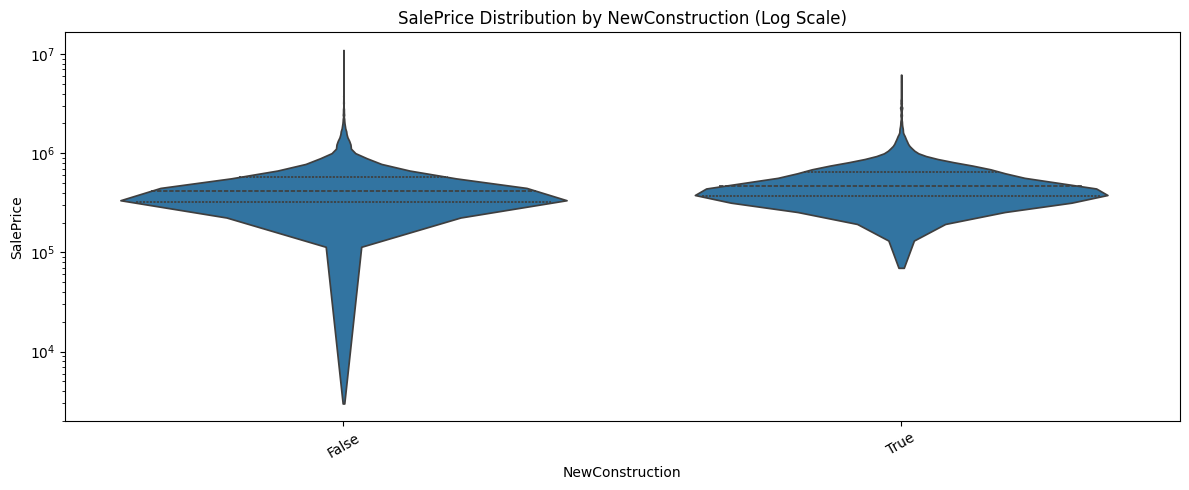


Summary by NewConstruction
                 count    median       mean        std
NewConstruction                                       
True              2390  462682.5  557077.44  356293.36
False            20277  419900.0  502244.94  345104.44


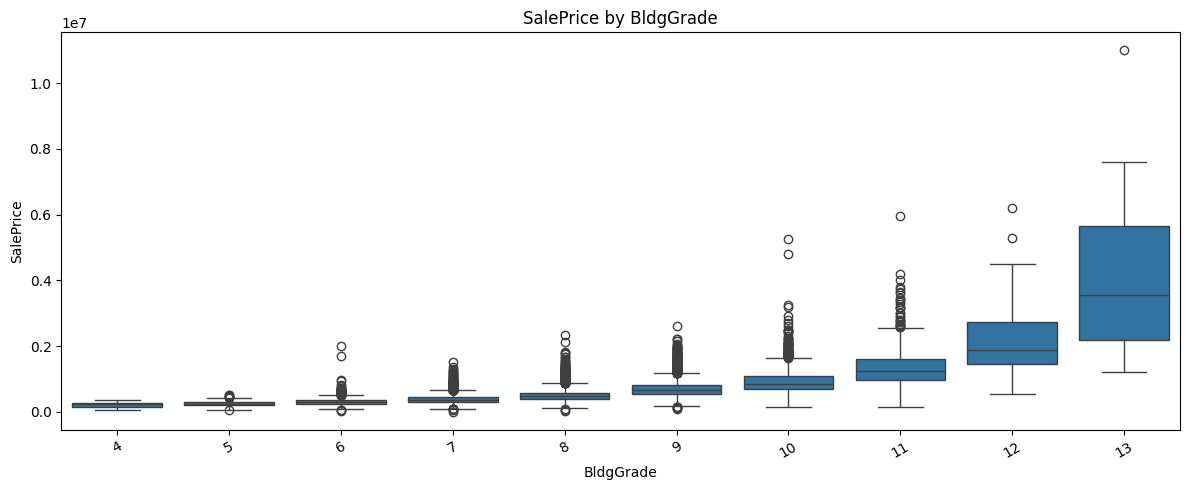

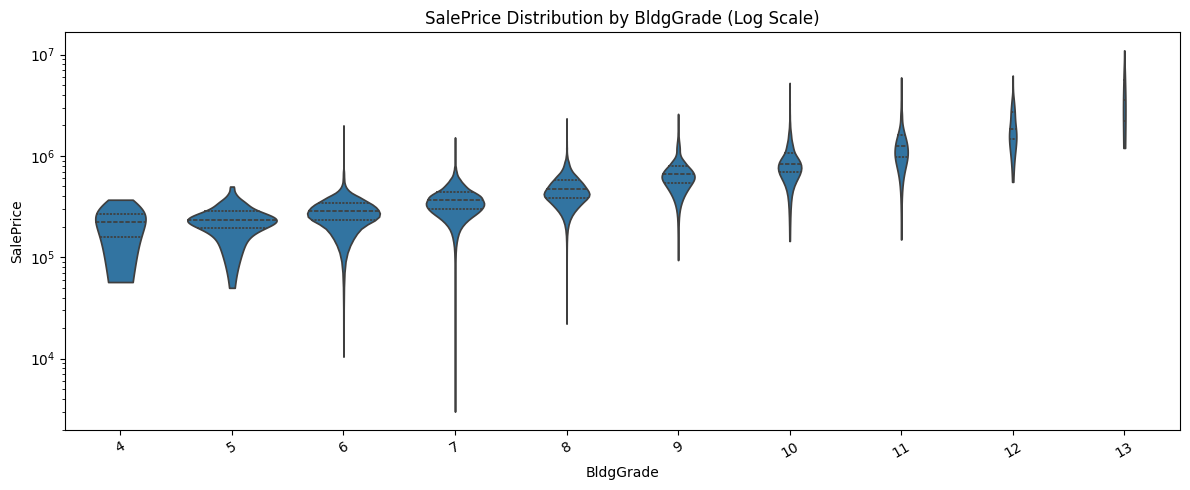


Summary by BldgGrade
           count     median        mean         std
BldgGrade                                          
13            18  3560000.0  4092233.33  2566713.46
12           121  1865000.0  2166367.43   972419.96
11           439  1250000.0  1395871.36   666522.91
10          1205   839950.0   939515.27   424442.36
9           2824   659700.0   711610.60   273862.39
8           6252   470000.0   501990.94   175462.25
7           9496   364675.5   380718.13   122640.47
6           2104   285000.0   295245.44   105772.34
5            196   235000.0   243008.30    81566.98
4             12   223975.0   215037.50   100952.05


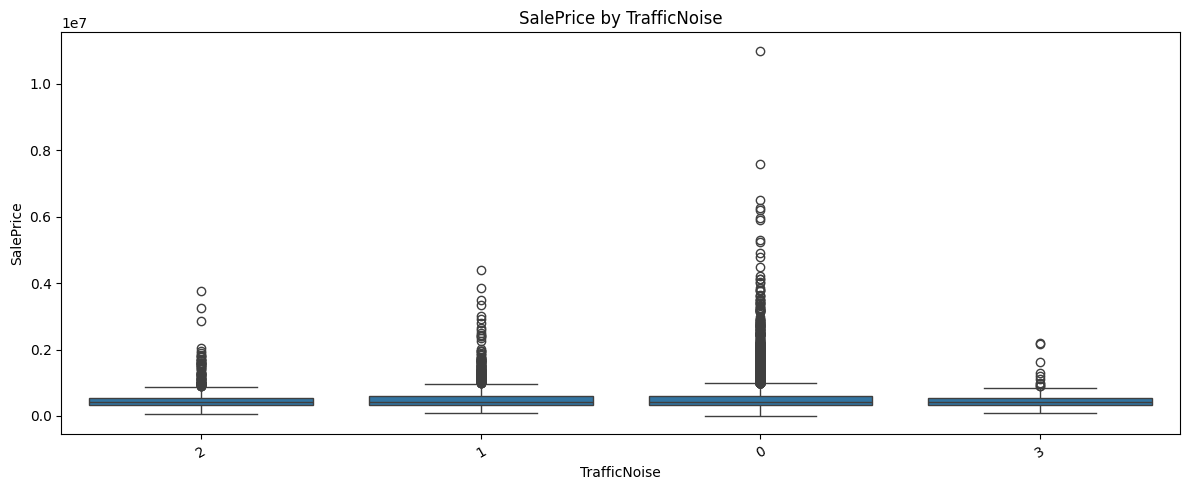

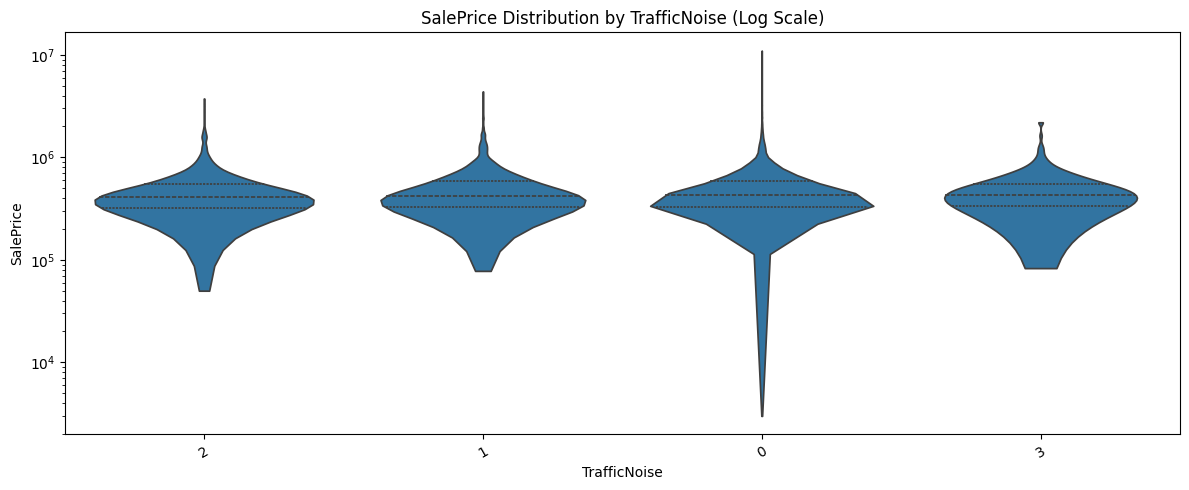


Summary by TrafficNoise
              count    median       mean        std
TrafficNoise                                       
3               161  427000.0  485009.06  290365.17
0             19473  425000.0  508779.09  348740.30
1              1894  420000.0  516322.15  353138.24
2              1139  410000.0  484617.87  305084.04


In [32]:

# Column whose distribution we want to analyze:
target = "SalePrice"

# Categorical variables used to compare sale prices:
group_cols = [
    "PropertyType",
    "NewConstruction",
    "BldgGrade",
    "TrafficNoise"
]

for col in group_cols:
    # Create a new figure for the boxplot
    plt.figure(figsize=(12, 5))
    # index:-This makes comparisons between categories easier.
    order = (
        cleaned.groupby(col)[target]
        .median()
        .sort_values()
        .index
    )

    sns.boxplot(data=cleaned, x=col, y=target, order=order)
    plt.title(f"SalePrice by {col}")

    # Rotate category labels to prevent them from overlapping
    plt.xticks(rotation=30)

    # Adjust spacing so labels and titles fit properly
    plt.tight_layout()

    plt.show()

    # Create a separate figure for the violin plot
    plt.figure(figsize=(12, 5))

    # Draw a violin plot to visualize the distribution's shape.
    # Wider sections indicate areas with more observations.
    # inner="quartile" displays the quartiles inside each violin.
    # cut=0 prevents the estimated density from extending
    # beyond the observed minimum and maximum values.
    sns.violinplot(
        data=cleaned,
        x=col,
        y=target,
        order=order,
        inner="quartile",
        cut=0
    )

    # Use a logarithmic y-axis to make low and high prices
    # easier to compare when prices are highly right-skewed.
    # All SalePrice values must be strictly positive for this scale.
    plt.yscale("log")

    # Add a title describing the variable being compared
    plt.title(f"SalePrice Distribution by {col} (Log Scale)")

    # Rotate category labels for readability
    plt.xticks(rotation=30)

    # Improve the figure layout
    plt.tight_layout()

    # Display the violin plot
    plt.show()

    summary = (
        cleaned.groupby(col)[target]
        .agg(["count", "median", "mean", "std"])
        .sort_values("median", ascending=False)
    )

    # Print the name of the categorical variable being analyzed
    print(f"\nSummary by {col}")

    # Display the summary table rounded to two decimal places
    print(summary.round(2))


#Modality check on SalePrice

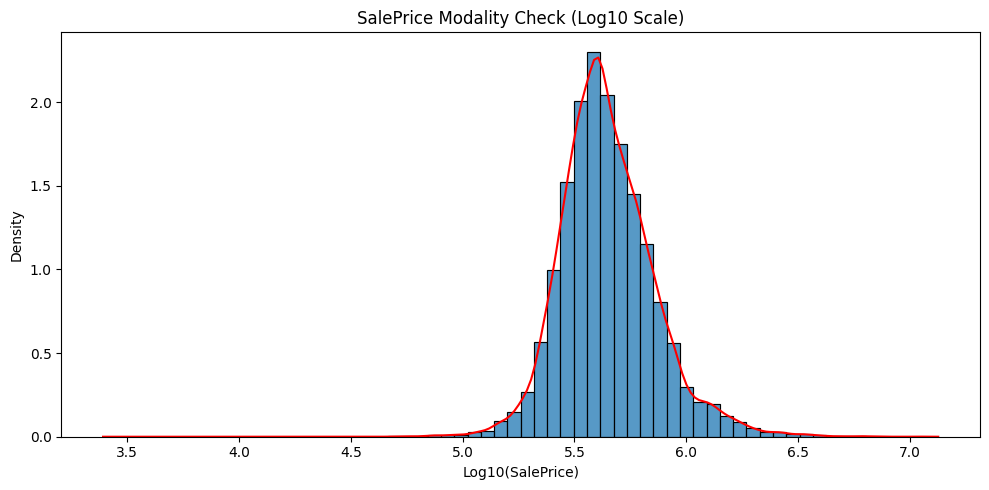

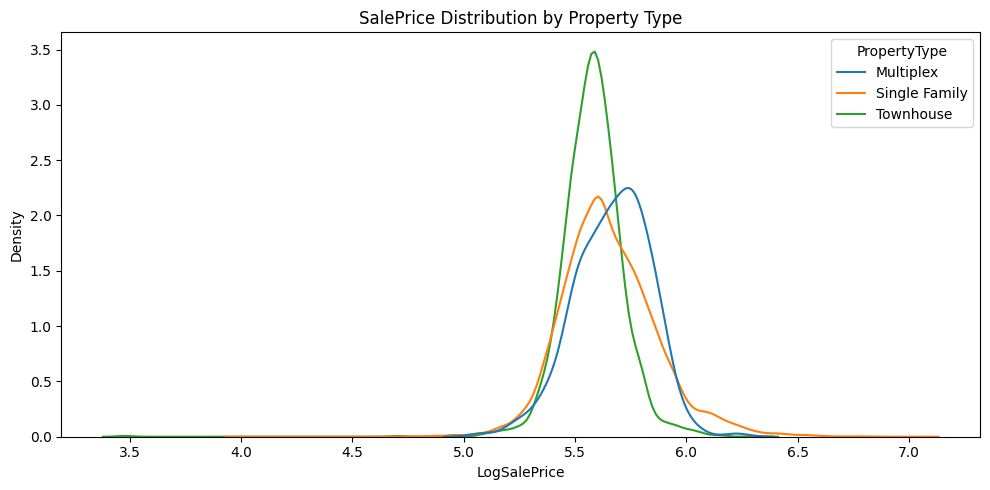

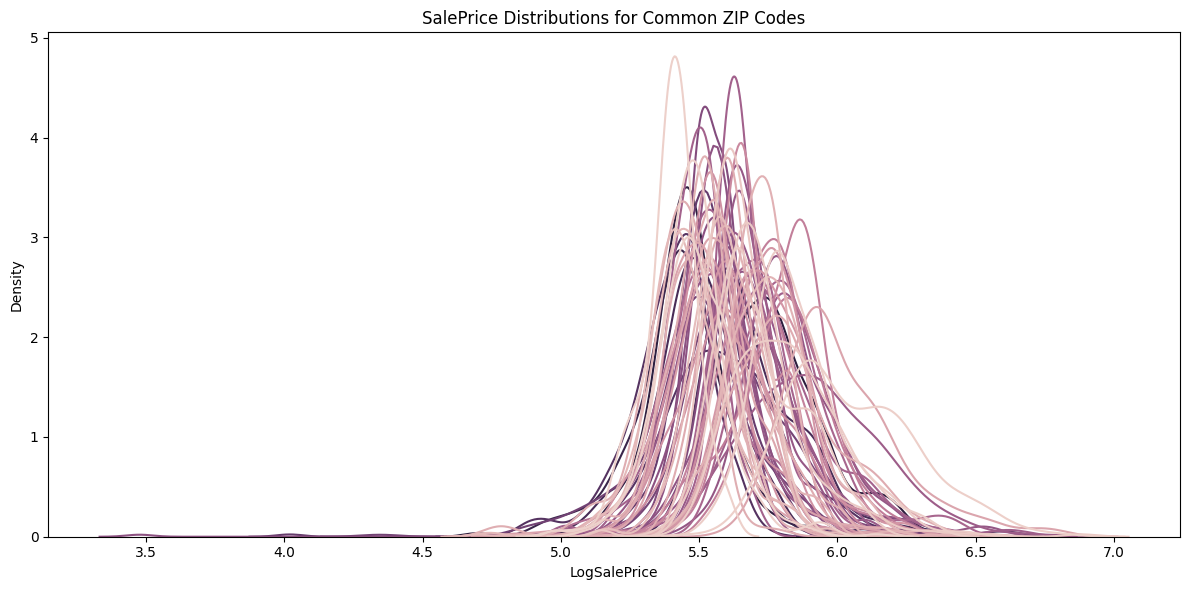

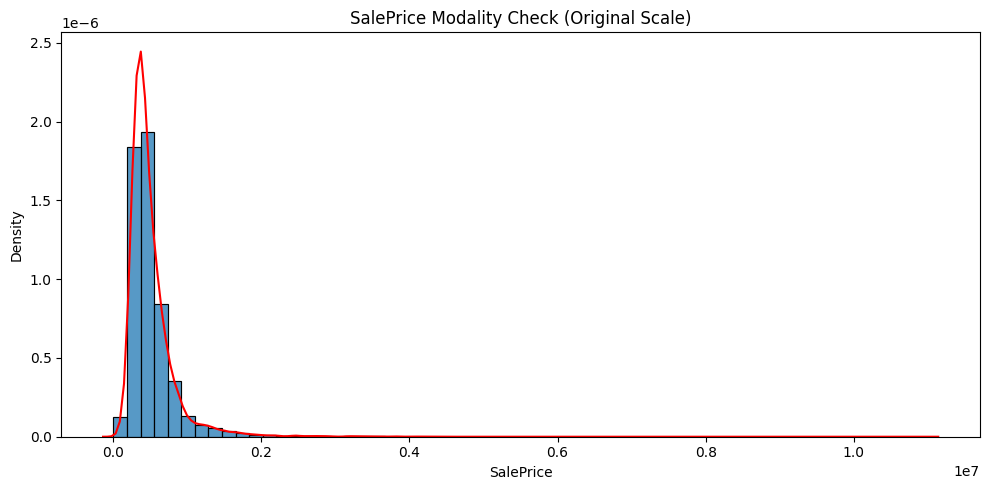

In [33]:
# Overall distribution: log transformation makes the right tail easier to inspect
cleaned["LogSalePrice"] = np.log10(cleaned["SalePrice"].where(cleaned["SalePrice"] > 0))

plt.figure(figsize=(10, 5))
sns.histplot(cleaned["LogSalePrice"].dropna(), bins=60, stat="density")
sns.kdeplot(cleaned["LogSalePrice"].dropna(), color="red")
plt.title("SalePrice Modality Check (Log10 Scale)")
plt.xlabel("Log10(SalePrice)")
plt.tight_layout()
plt.show()

# Compare property types
plt.figure(figsize=(10, 5))
sns.kdeplot(
    data=cleaned, x="LogSalePrice",
    hue="PropertyType", common_norm=False
)
plt.title("SalePrice Distribution by Property Type")
plt.tight_layout()
plt.show()

# Compare ZIP codes with at least 100 sales
zip_counts = cleaned["ZipCode"].value_counts()
common_zips = zip_counts[zip_counts >= 100].index

plt.figure(figsize=(12, 6))
sns.kdeplot(
    data=cleaned[cleaned["ZipCode"].isin(common_zips)],
    x="LogSalePrice", hue="ZipCode",
    common_norm=False, legend=False
)
plt.title("SalePrice Distributions for Common ZIP Codes")
plt.tight_layout()
plt.show()



# Overall SalePrice distribution without log transformation
# This helps identify skewness and possible multiple peaks
# using the original sale prices.

plt.figure(figsize=(10, 5))

# Plot a histogram with density normalization
# so it can be compared with the KDE curve.
sns.histplot(
    data=cleaned,
    x="SalePrice",
    bins=60,
    stat="density"
)

# Add a KDE curve to estimate the distribution's shape
sns.kdeplot(
    data=cleaned,
    x="SalePrice",
    color="red"
)

# Add the title and axis labels
plt.title("SalePrice Modality Check (Original Scale)")
plt.xlabel("SalePrice")
plt.ylabel("Density")

# Prevent labels and titles from being cut off
plt.tight_layout()

# Display the plot
plt.show()


#Tail behavior: share of total value from the top 1% and 10% of sales

In [34]:
prices = cleaned["SalePrice"].dropna()
total_value = prices.sum()

results = []

for percentage in [0.01, 0.10]:
    n = int(np.ceil(len(prices) * percentage))

    # Select the highest-priced sales
    top_sales = prices.nlargest(n)
    top_value = top_sales.sum()

    results.append({
        "Top Percentage": f"{percentage:.0%}",
        "Number of Sales": n,
        "Minimum Price in Group": top_sales.min(),
        "Group Sales Value": top_value,
        "Share of Total Sales Value (%)":
            round(top_value / total_value * 100, 2)
    })

results_df = pd.DataFrame(results)
print("Total sales value:", total_value)
print(results_df.to_string(index=False))


Total sales value: 11515435658
Top Percentage  Number of Sales  Minimum Price in Group  Group Sales Value  Share of Total Sales Value (%)
            1%              227                 1800000          604643791                            5.25
           10%             2267                  804950         2817718869                           24.47


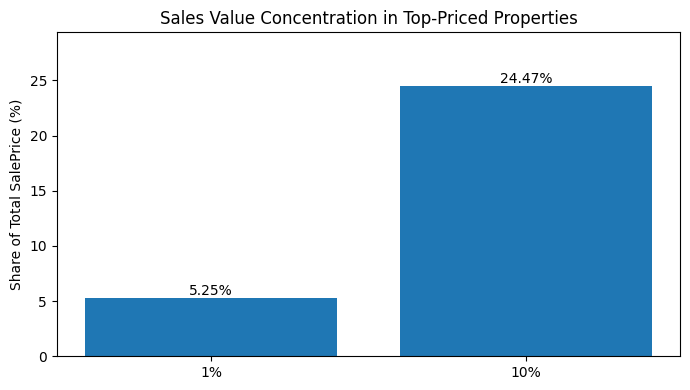

In [35]:
labels = results_df["Top Percentage"]
shares = results_df["Share of Total Sales Value (%)"]

plt.figure(figsize=(7, 4))
bars = plt.bar(labels, shares)

plt.bar_label(bars, fmt="%.2f%%")
plt.ylabel("Share of Total SalePrice (%)")
plt.title("Sales Value Concentration in Top-Priced Properties")
plt.ylim(0, max(shares) * 1.2)
plt.tight_layout()
plt.show()


#B.Normality

# Shapiro-Wilk Test (Quick Glance)

## What it does
Tests whether a sample came from a **normally distributed** population.

- **H₀:** data is normal
- **H₁:** data is not normal
- **p > 0.05** → fail to reject H₀ (no evidence against normality)
- **p ≤ 0.05** → reject H₀ (data likely not normal)

## Core idea
If data is normal, the sorted sample values line up almost perfectly with what you'd expect from a normal distribution (points on a Q-Q plot fall on a straight line). **W** measures how well they line up.

## Formula

$$W = \frac{\left(\sum_{i=1}^{n} a_i \, x_{(i)}\right)^2}{\sum_{i=1}^{n} (x_i - \bar{x})^2}$$

- $x_{(i)}$ = i-th smallest value (ordered sample)
- $\bar{x}$ = sample mean
- $a_i$ = pre-computed constants from the expected values and covariances of normal order statistics:

$$(a_1, \dots, a_n) = \frac{m^\top V^{-1}}{\sqrt{m^\top V^{-1} V^{-1} m}}$$

where $m$ = expected order statistics of a standard normal, $V$ = their covariance matrix.

**Intuition**
- **Numerator** = squared best-fit slope of a normal Q-Q line (weighted combination of ordered data)
- **Denominator** = total variance (sum of squares around the mean)
- **W** ≈ squared correlation between the ordered data and normal scores

## Interpreting W
- **W ≈ 1** → very close to normal
- **W much less than 1** → departs from normality
- Range: $0 < W \le 1$

## Process
1. Sort the data: $x_{(1)} \le x_{(2)} \le \dots \le x_{(n)}$
2. Get coefficients $a_i$ for your sample size n (tables or software)
3. Numerator: $(\sum a_i x_{(i)})^2$
4. Denominator: $\sum (x_i - \bar{x})^2$
5. $W$ = numerator / denominator
6. Convert W to a p-value (tables or approximation)
7. Compare p-value with α (usually 0.05)

## Limitations
| Issue | Why it matters |
|---|---|
| **Large samples** | With thousands of points, tiny harmless deviations become "significant" |
| **Small samples** | With n < ~20, low power: can miss real non-normality |
| **Sample size cap** | Original: n ≤ 50. Royston's extension: up to ~5000 (SciPy warns beyond that) |
| **Ties / repeated values** | Reduces accuracy; works best on continuous data |
| **Outliers** | Sensitive; can cause rejection even if most data is normal |
| **Only tests normality** | Doesn't say *how* data deviates (skew vs heavy tails) |
| **"Fail to reject" ≠ "is normal"** | Absence of evidence isn't proof; confirm visually |
| **Residuals vs raw data** | For regression/ANOVA, test the **residuals** |

## Practical tips
- Always pair with a **Q-Q plot** and **histogram**
- For large n, rely more on visuals and effect size than the p-value
- If non-normal: try transformations (log, Box-Cox) or non-parametric tests

> **One-line summary:** Shapiro-Wilk checks how closely sorted data matches a straight line on a normal Q-Q plot; W near 1 means normal, a small p-value means not normal, but it's over-sensitive for large samples and underpowered for tiny ones.

# D'Agostino-Pearson Test (Quick Glance)

## What it does
Tests whether a sample came from a **normally distributed** population by checking its **skewness** and **kurtosis**.

- **H₀:** data is normal
- **H₁:** data is not normal
- **p > 0.05** → fail to reject H₀ (no evidence against normality)
- **p ≤ 0.05** → reject H₀ (data likely not normal)

## Core idea
A normal distribution has skewness = 0 (symmetric) and kurtosis = 3 (normal tails). The test measures how far your sample's skewness and kurtosis are from those values, then combines both gaps into one statistic **K²**.

## Formula

$$K^2 = Z_1(\sqrt{b_1})^2 + Z_2(b_2)^2$$

- Sample skewness: $\sqrt{b_1} = \dfrac{m_3}{m_2^{3/2}}$
- Sample kurtosis: $b_2 = \dfrac{m_4}{m_2^{2}}$
- $m_k = \dfrac{1}{n}\sum (x_i - \bar{x})^k$ (the k-th central moment)
- $Z_1$ = skewness converted to an approximately standard-normal score (D'Agostino transformation)
- $Z_2$ = kurtosis converted to an approximately standard-normal score (Anscombe-Glynn transformation)
- Under H₀, $K^2 \sim \chi^2$ with **2 degrees of freedom**

**Intuition**
- $Z_1^2$ = "how lopsided is the data?"
- $Z_2^2$ = "how heavy or light are the tails?"
- **K²** = both added together, so either problem can trigger rejection

## Interpreting K²
- **K² near 0** → skewness and kurtosis look normal
- **Large K²** (small p) → data is skewed, has odd tails, or both
- Range: $K^2 \ge 0$

## Process
1. Compute the central moments $m_2, m_3, m_4$
2. Compute skewness $\sqrt{b_1}$ and kurtosis $b_2$
3. Transform each into a Z-score ($Z_1$, $Z_2$)
4. $K^2 = Z_1^2 + Z_2^2$
5. Get the p-value from the $\chi^2_2$ distribution
6. Compare the p-value with α (usually 0.05)

## Limitations
| Issue | Why it matters |
|---|---|
| **Small samples** | Needs n ≥ 8; the kurtosis part is unreliable below ~20 |
| **Large samples** | Tiny harmless skew or tail differences become "significant" |
| **Outliers** | Moments (especially the 4th) are very sensitive to extreme values |
| **Insensitive to other shapes** | Can miss non-normality that keeps skew ≈ 0 and kurtosis ≈ 3 |
| **"Fail to reject" ≠ "is normal"** | Confirm visually |
| **Residuals vs raw data** | For regression/ANOVA, test the **residuals** |

## Practical tips
- Check `skew()` and `kurtosis()` separately to see *why* it failed
- House prices usually fail on **positive skew**, which a log or power transform often fixes
- Pair with a Q-Q plot and histogram

> **One-line summary:** D'Agostino-Pearson combines skewness and kurtosis into one chi-square statistic; a small p-value means the data is lopsided, has unusual tails, or both.

# K-S Test with Lilliefors Correction (Quick Glance)

## What it does
Tests whether a sample came from a **normal distribution** by finding the **largest gap** between the sample's cumulative curve and a fitted normal's cumulative curve.

- **H₀:** data is normal
- **H₁:** data is not normal
- **p > 0.05** → fail to reject H₀
- **p ≤ 0.05** → reject H₀

## Core idea
Draw the empirical CDF (a staircase built from your data) and the CDF of a normal with the sample's mean and standard deviation. If the data is normal, the two curves hug each other. **D** is the biggest vertical distance between them.

## Formula

$$D = \sup_x \left| F_n(x) - \Phi\!\left(\frac{x - \bar{x}}{s}\right) \right|$$

- $F_n(x)$ = empirical CDF = (number of points ≤ x) / n
- $\Phi$ = standard normal CDF
- $\bar{x}, s$ = sample mean and standard deviation (**estimated from the data**)
- $\sup$ = the maximum over all x

**Why Lilliefors?**
- The classic K-S test assumes the mean and SD are **known in advance**
- When you estimate them from the same data, the fit is artificially good, so D is smaller than the classic K-S table expects and its p-values come out **too large**
- **Lilliefors** keeps the same D but uses corrected critical values (found by simulation)

## Interpreting D
- **D near 0** → sample CDF matches the normal CDF
- **Large D** → clear gap, so not normal
- Range: $0 \le D \le 1$

## Process
1. Standardize: $z_i = (x_i - \bar{x})/s$
2. Sort the data and build the empirical CDF
3. Compute the normal CDF at each point
4. D = the largest absolute difference
5. Get the p-value from Lilliefors' simulated distribution (`statsmodels.lilliefors`)
6. Compare the p-value with α

## Limitations
| Issue | Why it matters |
|---|---|
| **Lower power** | Usually weaker than Shapiro-Wilk and Anderson-Darling |
| **Center-focused** | Most sensitive near the middle of the distribution, weaker in the tails |
| **Plain `kstest` after fitting** | Gives wrong (too large) p-values; use Lilliefors |
| **Ties / discrete data** | Distorts the CDF gaps |
| **Large samples** | Trivial deviations become significant |
| **"Fail to reject" ≠ "is normal"** | Confirm visually |

## Practical tips
- Treat it as a **secondary** check, not the main one
- If it disagrees with Shapiro-Wilk or Anderson-Darling, trust those and the Q-Q plot more
- Always pair with a Q-Q plot

> **One-line summary:** Lilliefors measures the biggest gap between your data's CDF and a fitted normal CDF, with a corrected p-value for estimated parameters; it's easy to understand but the least powerful of the four tests.

# Anderson-Darling Test (Quick Glance)

## What it does
Tests whether a sample came from a **normal distribution**, with **extra weight on the tails**.

- **H₀:** data is normal
- **H₁:** data is not normal
- **A² < critical value** → fail to reject H₀
- **A² > critical value** → reject H₀

SciPy's `anderson()` returns the statistic and critical values at several significance levels (15%, 10%, 5%, 2.5%, 1%), not a p-value.

## Core idea
Like K-S, it compares the empirical CDF with the normal CDF. But instead of only the single biggest gap, it **sums the squared gaps across the whole range** and **weights the tails more heavily**.

## Formula

$$A^2 = -n - \frac{1}{n}\sum_{i=1}^{n} (2i-1)\left[\ln F(z_{(i)}) + \ln\big(1 - F(z_{(n+1-i)})\big)\right]$$

- $z_{(i)} = (x_{(i)} - \bar{x})/s$ = i-th smallest standardized value
- $F$ = standard normal CDF
- The **tail weighting** comes from the log terms: $\ln F$ and $\ln(1-F)$ blow up when F is near 0 or 1

**Intuition**
- Squared gaps between the two CDFs are added up over all points
- Gaps in the **tails** count extra, so outliers and heavy tails are caught quickly

## Interpreting A²
- **Small A²** → close fit to normal
- **Large A²** → poor fit
- Range: $A^2 \ge 0$
- Compare to the critical value at your α. In SciPy, `critical_values[2]` is the **5%** level.

## Process
1. Standardize the data with sample mean and SD
2. Sort the values
3. Compute the normal CDF at each sorted value
4. Plug into the A² formula
5. Compare A² with the critical value (SciPy's values already account for estimated parameters)
6. Reject normality if A² > critical value

## Limitations
| Issue | Why it matters |
|---|---|
| **No direct p-value in SciPy** | You compare to critical values at fixed levels only |
| **Very sensitive to outliers** | A few extreme points can trigger rejection |
| **Large samples** | Tiny deviations become significant |
| **Ties / rounded data** | Reduces accuracy |
| **Direction is reversed vs p-values** | **Bigger A² = worse**, unlike p-values where bigger = better |
| **"Fail to reject" ≠ "is normal"** | Confirm visually |

## Practical tips
- Best choice when **tail behavior** matters (outliers, risk, extreme prices)
- In Figure 3, bars **below** the red line mean fail to reject normality
- Pair with a Q-Q plot, since tail problems show up as curved ends

> **One-line summary:** Anderson-Darling compares your data's CDF with a normal CDF while weighting the tails heavily; if A² exceeds the critical value, the data isn't normal.

# Box-Cox Transformation (Quick Glance)

## What it does
Applies a **power transformation** to reduce skewness and make data **closer to normal**. The best power λ is chosen automatically.

- It's a **transformation**, not a test
- Used before regression, t-tests, ANOVA, or anything that prefers roughly normal data or stable variance
- **Requires all values > 0**

## Core idea
Raise the data to a power λ. Different λ values give different "strengths" of correction, and Box-Cox searches for the λ that makes the transformed data look most normal.

## Formula

$$y(\lambda) = \begin{cases} \dfrac{x^{\lambda} - 1}{\lambda}, & \lambda \ne 0 \\ \ln x, & \lambda = 0 \end{cases}$$

**How λ is chosen:** by **maximum likelihood**, picking the λ that maximizes

$$\ell(\lambda) = -\frac{n}{2}\ln \hat{\sigma}^2(\lambda) + (\lambda - 1)\sum_{i=1}^{n} \ln x_i$$

where $\hat{\sigma}^2(\lambda)$ is the variance of the transformed data.

## Reading λ
| λ | Equivalent transform |
|---|---|
| **1** | No change (shifted only) |
| **0.5** | Roughly square root |
| **0** | Natural log |
| **-0.5** | Reciprocal square root |
| **-1** | Reciprocal (1/x) |

- **λ < 1** pulls in a long **right tail** (typical for prices)
- **λ > 1** pulls in a long **left tail**

## Process
1. Confirm all values are > 0
2. Search for the λ that maximizes the log-likelihood
3. Apply the formula with that λ
4. Check the result with a histogram, Q-Q plot, and normality tests
5. In SciPy: `transformed, lam = boxcox(x)`

## Limitations
| Issue | Why it matters |
|---|---|
| **Positive data only** | Fails on zeros or negatives |
| **Doesn't guarantee normality** | It finds the *best* power, not a perfect fit |
| **Sensitive to outliers** | Extreme values can distort λ |
| **Harder to interpret** | Coefficients are on the transformed scale |
| **Back-transforming predictions** | Needs care to return to the original units |
| **λ estimated from data** | Fit on training data only, to avoid leakage in ML pipelines |

## Practical tips
- If λ is close to 0, a plain **log** is easier to explain
- Report the λ you got
- Always verify with a Q-Q plot after transforming

> **One-line summary:** Box-Cox finds the power λ that makes positive data look most normal, generalizing log, square root, and reciprocal transforms in one formula.

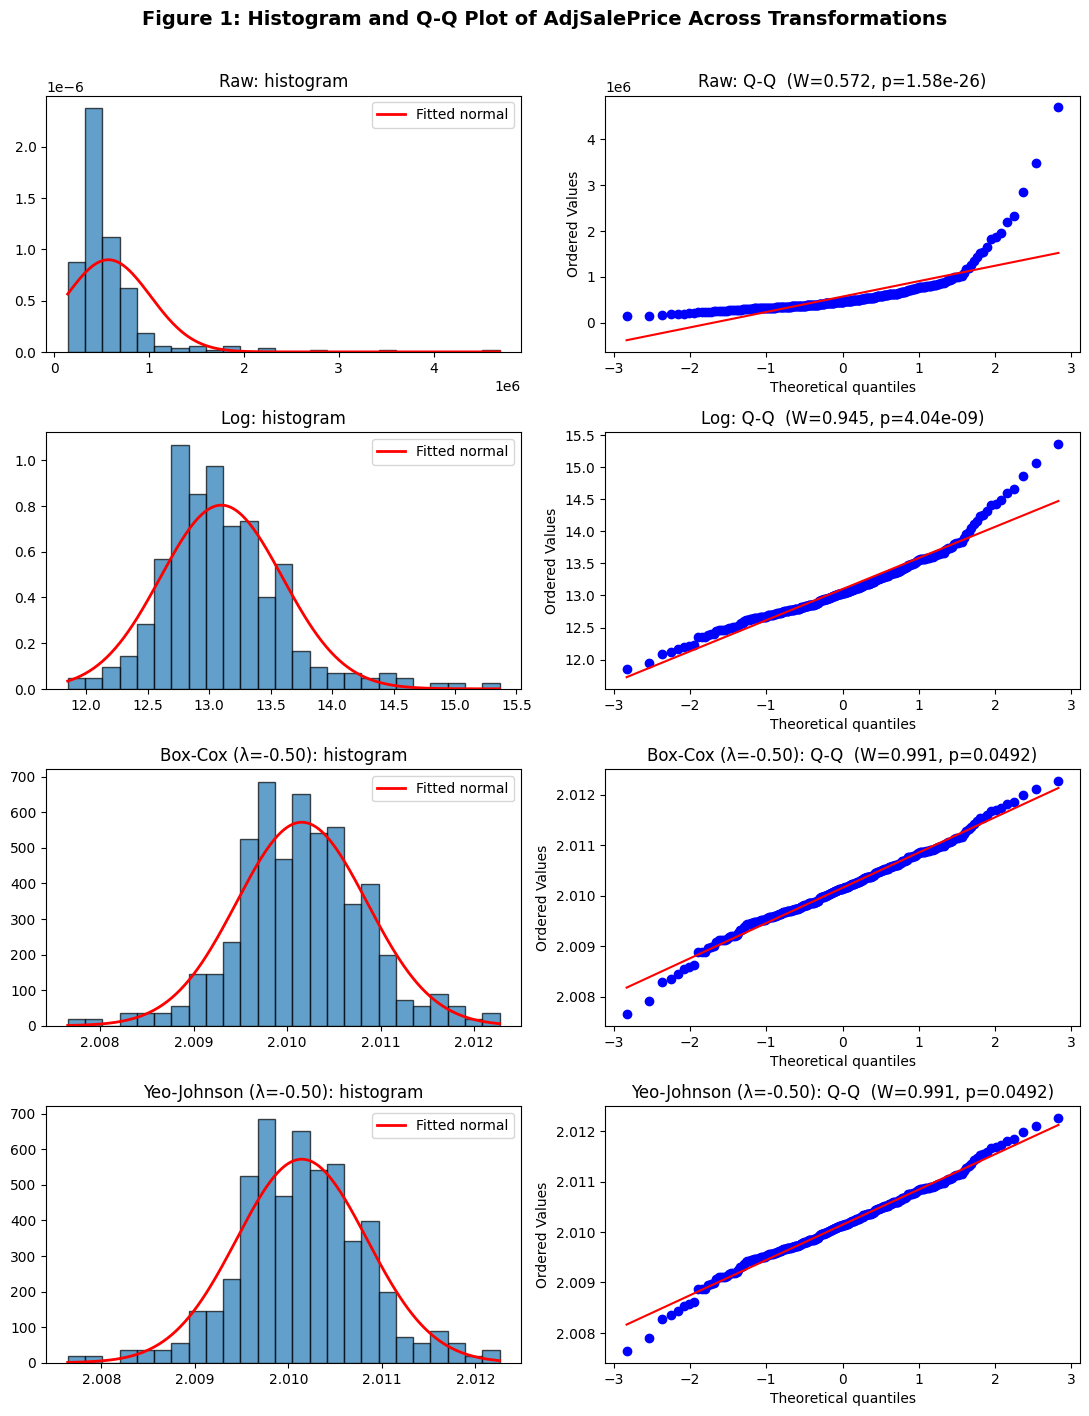

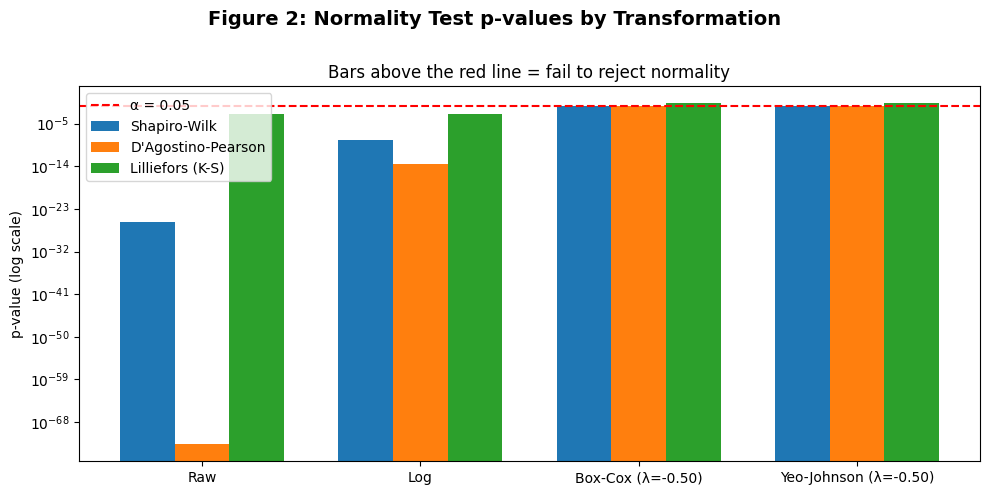

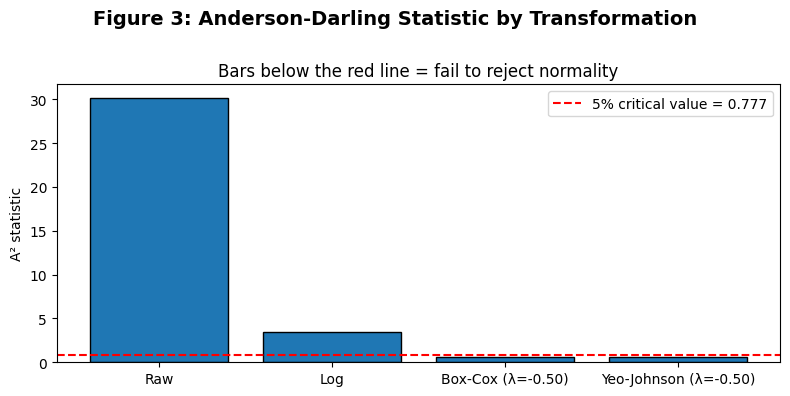

In [36]:
from scipy.stats import shapiro, normaltest, boxcox, yeojohnson
from statsmodels.stats.diagnostic import lilliefors

# --- Sample + prices ---
total_rows_needed = 300
sample_df = cleaned.sample(n=total_rows_needed, random_state=42)
prices = sample_df['AdjSalePrice'].dropna()

# --- Build the 4 versions of the data ---
log_prices = np.log(prices)
bc, lam_bc = boxcox(prices)            # needs prices > 0
yj, lam_yj = yeojohnson(prices)

datasets = {
    "Raw": np.asarray(prices),
    "Log": np.asarray(log_prices),
    f"Box-Cox (λ={lam_bc:.2f})": np.asarray(bc),
    f"Yeo-Johnson (λ={lam_yj:.2f})": np.asarray(yj),
}

def finish(fig, title, filename):
    """Give the figure a name, lay it out, save it, show it."""
    fig.suptitle(title, fontsize=14, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    fig.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()

# --- Figure 1: histogram (with fitted normal curve) + Q-Q plot ---
fig, axes = plt.subplots(len(datasets), 2, figsize=(11, 3.6 * len(datasets)))
for row, (name, d) in enumerate(datasets.items()):
    W, p = shapiro(d)

    ax = axes[row, 0]
    ax.hist(d, bins=25, density=True, edgecolor="black", alpha=0.7)
    xs = np.linspace(d.min(), d.max(), 300)
    ax.plot(xs, stats.norm.pdf(xs, d.mean(), d.std(ddof=1)), "r-", lw=2,
            label="Fitted normal")
    ax.set_title(f"{name}: histogram")
    ax.legend()

    stats.probplot(d, dist="norm", plot=axes[row, 1])
    axes[row, 1].set_title(f"{name}: Q-Q  (W={W:.3f}, p={p:.3g})")

finish(fig,
       "Figure 1: Histogram and Q-Q Plot of AdjSalePrice Across Transformations",
       "fig1_histogram_qq_transformations.png")

# --- Figure 2: p-values for each test x each transformation ---
tests = {
    "Shapiro-Wilk":       lambda x: shapiro(x)[1],
    "D'Agostino-Pearson": lambda x: normaltest(x)[1],
    "Lilliefors (K-S)":   lambda x: lilliefors(x, dist="norm")[1],
}

names = list(datasets.keys())
width = 0.25
xpos = np.arange(len(names))

fig, ax = plt.subplots(figsize=(10, 5))
for i, (tname, fn) in enumerate(tests.items()):
    pvals = [max(fn(d), 1e-300) for d in datasets.values()]   # avoid log(0)
    ax.bar(xpos + i * width, pvals, width, label=tname)

ax.axhline(0.05, color="red", ls="--", label="α = 0.05")
ax.set_yscale("log")
ax.set_xticks(xpos + width)
ax.set_xticklabels(names)
ax.set_ylabel("p-value (log scale)")
ax.set_title("Bars above the red line = fail to reject normality")
ax.legend()

finish(fig,
       "Figure 2: Normality Test p-values by Transformation",
       "fig2_normality_pvalues.png")

# --- Figure 3: Anderson-Darling statistic vs critical value ---
ad_stats = [stats.anderson(d, dist="norm").statistic for d in datasets.values()]
ad_crit = stats.anderson(list(datasets.values())[0], dist="norm").critical_values[2]  # 5% level

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(names, ad_stats, edgecolor="black")
ax.axhline(ad_crit, color="red", ls="--", label=f"5% critical value = {ad_crit:.3f}")
ax.set_ylabel("A² statistic")
ax.set_title("Bars below the red line = fail to reject normality")
ax.legend()

finish(fig,
       "Figure 3: Anderson-Darling Statistic by Transformation",
       "fig3_anderson_darling.png")